# 01. Анализ пиковой нагрузки сервиса

**Тип работы:** учебный аналитический кейс  
**Инструменты:** Python, pandas, matplotlib, Jupyter Notebook  
**Данные:** примеры из условия задачи; для проверки скорости — сгенерированные запросы.


## 1. Постановка задачи

### Контекст

Во время крупных распродаж онлайн-магазин обрабатывает много запросов одновременно. Каждый запрос работает определённое время и занимает часть ресурсов сервера. Если несколько запросов выполняются одновременно, их нагрузка складывается.

### Цель

Определить максимальную суммарную нагрузку на сервер и самый ранний момент её достижения для оценки потребности в вычислительных ресурсах.

### План работы

1. Разобраться во входных данных и проверить небольшой пример.
2. Попробовать простой перебор и оценить его ограничения.
3. Реализовать более эффективный алгоритм.
4. Проверить ответ на тестах и показать изменение нагрузки на графике.
5. Измерить время выполнения на больших наборах запросов.


## 2. Данные и ограничения

Каждый запрос описывается тремя параметрами:

| Параметр | Описание |
|---|---|
| `start` | Время начала запроса |
| `end` | Время завершения запроса |
| `cost` | Количество потребляемых ресурсов |

Запрос активен на интервале `[start, end)`: момент начала включается, а момент завершения — нет.

По условию количество запросов может достигать **200 000**, время — **1 000 000 000**, а нагрузка одного запроса — от **1 до 10 000**. Всегда `start < end`.

Для первого эксперимента возьму **пример № 1 из условия**, чтобы проверить расчёты на известных значениях. Это учебные данные, не реальные серверные логи.


In [1]:
import pandas as pd

# Пример 1 из условия задачи Яндекса
requests = [
    (0, 10, 5),
    (3, 8, 4),
    (8, 12, 6),
    (5, 6, 100)
]

df = pd.DataFrame(
    requests,
    columns=["start", "end", "cost"]
)

df

,start,end,cost
0,0,10,5
1,3,8,4
2,8,12,6
3,5,6,100


### Проверка данных

Перед расчётами проверю размер таблицы, типы данных, пропуски и корректность временных интервалов.


In [2]:

# Размер таблицы
print("Размер таблицы:", df.shape)

# Типы данных
print("\nТипы данных:")
print(df.dtypes)

# Пропущенные значения
print("\nПропуски:")
print(df.isna().sum())

# Проверка условий
print("\nКорректные интервалы:", (df["start"] < df["end"]).all())
print("Положительная нагрузка:", (df["cost"] > 0).all())


Размер таблицы: (4, 3)

Типы данных:
start    int64
end      int64
cost     int64
dtype: object

Пропуски:
start    0
end      0
cost     0
dtype: int64

Корректные интервалы: True
Положительная нагрузка: True


**Результат проверки.** В примере 4 запроса и 3 числовых столбца. Пропусков нет, начало каждого запроса раньше окончания, а нагрузка положительная. Можно переходить к расчётам.


## 3. Первый подход — простой перебор

Сначала попробую посчитать нагрузку отдельно для каждого момента времени: перебрать запросы, проверить, какие из них активны, и сложить их `cost`.

Для небольшого примера проверю моменты от 0 до 12 включительно.


In [3]:

# Проверяем нагрузку в каждый момент времени
for t in range(13):
    total = 0

    for start, end, cost in requests:
        if start <= t < end:
            total += cost

    print(f"Время: {t}, нагрузка: {total}")



Время: 0, нагрузка: 5
Время: 1, нагрузка: 5
Время: 2, нагрузка: 5
Время: 3, нагрузка: 9
Время: 4, нагрузка: 9
Время: 5, нагрузка: 109
Время: 6, нагрузка: 9
Время: 7, нагрузка: 9
Время: 8, нагрузка: 11
Время: 9, нагрузка: 11
Время: 10, нагрузка: 6
Время: 11, нагрузка: 6
Время: 12, нагрузка: 0


### Результат первого эксперимента

Максимальная нагрузка — **109 единиц в момент 5**. На примере этот способ сработал.

Но проверять каждый момент времени при диапазоне до миллиарда слишком долго. Попробую учитывать только моменты, когда нагрузка меняется.


## 4. Метод событий (Sweep Line)

Нагрузка меняется только в начале и в конце запроса:

- в момент `start` прибавляется `cost`;
- в момент `end` вычитается `cost`.

Если несколько событий происходят одновременно, сначала объединю их изменения. Затем отсортирую моменты времени и последовательно посчитаю общую нагрузку.


In [4]:

# Создаём события изменения нагрузки
changes = {}

for start, end, cost in requests:
    changes[start] = changes.get(start, 0) + cost
    changes[end] = changes.get(end, 0) - cost

# Сортируем события по времени
events = sorted(changes.items())

# Представляем результат в виде таблицы
events_df = pd.DataFrame(
    events,
    columns=["time", "load_change"]
)

events_df


,time,load_change
0,0,5
1,3,4
2,5,100
3,6,-100
4,8,2
5,10,-5
6,12,-6


**Результат.** Получилось 7 различных моментов изменения нагрузки. Например, в момент 8 один запрос заканчивается (`−4`), а другой начинается (`+6`), поэтому общее изменение равно `+2`.


### Расчёт суммарной нагрузки

Теперь добавлю столбец `current_load` с накопленной суммой изменений. Он покажет нагрузку после каждого момента события.


In [5]:

# Рассчитываем накопленную нагрузку
events_df["current_load"] = events_df["load_change"].cumsum()

# Выводим таблицу
events_df


,time,load_change,current_load
0,0,5,5
1,3,4,9
2,5,100,109
3,6,-100,9
4,8,2,11
5,10,-5,6
6,12,-6,0


### Поиск максимума

Найду наибольшее значение `current_load` и время его первого появления. Поскольку события отсортированы по времени, первый максимум и будет самым ранним.


In [6]:

# Находим максимальную нагрузку
max_load = events_df["current_load"].max()

# Находим строку первого максимума
peak_index = events_df["current_load"].idxmax()

# Получаем время пика
earliest_time = events_df.loc[peak_index, "time"]

print("Максимальная нагрузка:", max_load)
print("Время первого пика:", earliest_time)


Максимальная нагрузка: 109
Время первого пика: 5


**Результат.** Метод событий тоже дал **109 единиц в момент 5** — ответ совпал с простым перебором и примером из условия.


### Визуализация нагрузки

Построю ступенчатый график: между соседними событиями нагрузка не меняется, поэтому обычная наклонная линия здесь не подошла бы.


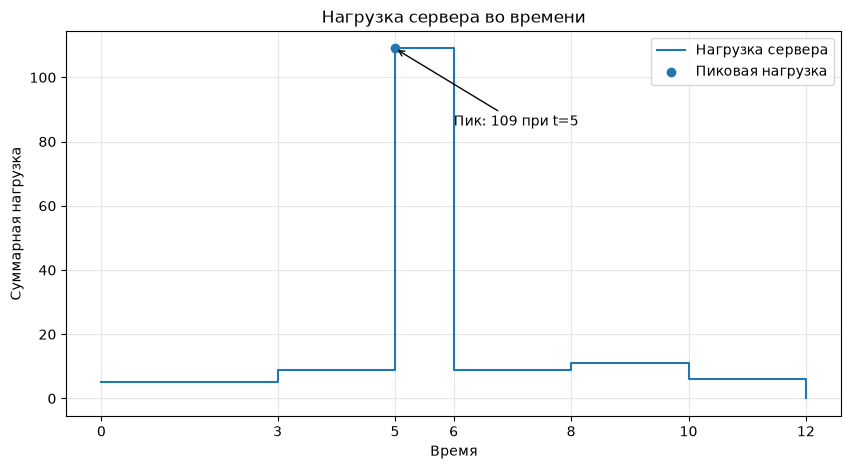

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Изменение нагрузки во времени
plt.step(
    events_df["time"],
    events_df["current_load"],
    where="post",
    label="Нагрузка сервера"
)

# Отмечаем максимальную нагрузку
plt.scatter(
    earliest_time,
    max_load,
    label="Пиковая нагрузка",
    zorder=3
)

plt.title("Нагрузка сервера во времени")
plt.xlabel("Время")
plt.ylabel("Суммарная нагрузка")

plt.xticks(events_df["time"])
plt.grid(alpha=0.3)
plt.legend()

plt.annotate(
    f"Пик: {max_load} при t={earliest_time}",
    xy=(earliest_time, max_load),
    xytext=(6, 85),
    arrowprops={"arrowstyle": "->"}
)

plt.show()


**Наблюдение.** Резкий скачок в момент 5 связан с запросом стоимостью 100 единиц на интервале `[5, 6)`. После его завершения нагрузка возвращается к 9.


## 5. Тестирование алгоритма

Чтобы проверять разные входные данные, вынесу алгоритм в функцию `find_peak()`. Затем запущу три примера из условия и два дополнительных сценария: один запрос и одновременное начало двух запросов.


In [9]:

def find_peak(requests):
    changes = {}

    # Собираем изменения нагрузки
    for start, end, cost in requests:
        changes[start] = changes.get(start, 0) + cost
        changes[end] = changes.get(end, 0) - cost

    current_load = 0
    max_load = 0
    earliest_time = 0

    # Обрабатываем события по времени
    for time in sorted(changes):
        current_load += changes[time]

        if current_load > max_load:
            max_load = current_load
            earliest_time = time

    return max_load, earliest_time


### Примеры из условия

Сначала проверю результаты, для которых в условии уже известен правильный ответ.


In [10]:

# Пример 1 — из условия
test_1 = [
    (0, 10, 5),
    (3, 8, 4),
    (8, 12, 6),
    (5, 6, 100)
]

# Пример 2 — один запрос завершается,
# когда начинается другой
test_2 = [
    (1, 5, 7),
    (5, 10, 11)
]

# Пример 3 — максимум повторяется
test_3 = [
    (0, 2, 10),
    (2, 4, 3),
    (4, 6, 10)
]

assert find_peak(test_1) == (109, 5)
assert find_peak(test_2) == (11, 5)
assert find_peak(test_3) == (10, 0)

print("Все три теста пройдены!")


Все три теста пройдены!


### Дополнительные случаи

Проверю минимальное количество запросов и совпадающие моменты начала.


In [11]:
# Один запрос
assert find_peak([(7, 20, 9)]) == (9, 7)

# Два запроса начинаются одновременно
assert find_peak([
    (2, 7, 5),
    (2, 4, 8)
]) == (13, 2)

print("Дополнительные тесты пройдены!")

Дополнительные тесты пройдены!


**Результат тестирования.** Все пять проверок прошли: функция вернула ожидаемые значения, в том числе при совпадении временных границ и повторении максимума. Это подтверждает работу на выбранных примерах, но не заменяет проверку на всех возможных входных данных.


## 6. Проверка производительности

Проверю, как растёт время работы `find_peak()` при увеличении количества запросов. Для этого сгенерирую наборы из 1 000, 10 000, 50 000 и 200 000 запросов.

Измеряю только выполнение функции, **без времени генерации данных**. Это один запуск для каждого размера, поэтому результаты зависят от компьютера и текущей нагрузки на него.


In [12]:

import random
import time

# Проверим разные размеры данных
sizes = [1000, 10000, 50000, 200000]

results = []
rng = random.Random(42)

for n in sizes:
    test_requests = []

    # Генерируем n случайных запросов
    for i in range(n):
        start = rng.randint(0, 10**9 - 10000)
        end = start + rng.randint(1, 10000)
        cost = rng.randint(1, 10000)

        test_requests.append((start, end, cost))

    # Засекаем время выполнения
    start_time = time.perf_counter()

    find_peak(test_requests)

    end_time = time.perf_counter()

    elapsed = end_time - start_time

    results.append((n, elapsed))

# Выводим результаты
benchmark_df = pd.DataFrame(
    results,
    columns=["Количество запросов", "Время (сек)"]
)

benchmark_df


,Количество запросов,Время (сек)
0,1000,0.000429
1,10000,0.004067
2,50000,0.015658
3,200000,0.107001


### График времени выполнения

Построю график по полученным измерениям, чтобы увидеть, как меняется время с ростом числа запросов.


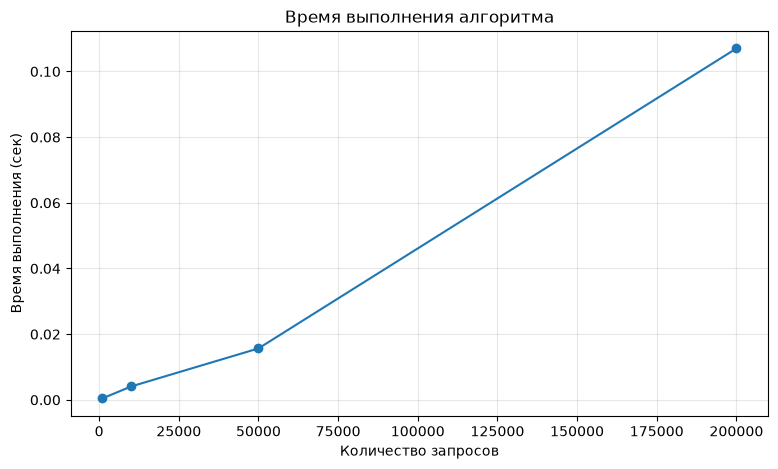

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    benchmark_df["Количество запросов"],
    benchmark_df["Время (сек)"],
    marker="o"
)

plt.title("Время выполнения алгоритма")
plt.xlabel("Количество запросов")
plt.ylabel("Время выполнения (сек)")

plt.grid(alpha=0.3)
plt.show()


**Результат.** Время работы увеличивается с ростом числа запросов. Значения конкретного запуска можно посмотреть в таблице и на графике выше; при повторном запуске они могут немного отличаться.

Временная сложность алгоритма — **`O(n log n)`** из-за сортировки событий, дополнительная память — **`O(n)`**. Для более точной оценки скорости полезно повторить измерения несколько раз.


## 7. Итоги

Сначала я проверила простой перебор, затем перешла к методу событий. Он позволяет не просматривать каждый момент времени, а работать только с началом и завершением запросов.

На примере из условия максимальная нагрузка составила **109 единиц в момент 5**. Алгоритм прошёл пять тестов. Отдельно проверила его скорость на сгенерированных наборах до **200 000 запросов**.

В этом проекте я попрактиковалась в работе со списками и словарями Python, сортировке, написании тестов и визуализации результатов в Jupyter Notebook.
